In [1]:
pip install sentence-transformers scikit-learn pandas numpy matplotlib seaborn

In [2]:
import pandas as pd

questions = [
    "What is the deadline for assignment submission?",
    "When is the last date to submit the assignment?",
    "How do I reset my college portal password?",
    "I forgot my portal password, how can I recover it?",
    "What are the exam timings for semester 5?",
    "Where can I find the library timings?",
    "What time does the library open?",
    "How to apply for a bonafide certificate?",
    "Process to get a bonafide certificate from college",
    "Is attendance mandatory for lab sessions?",
]

df = pd.DataFrame({"id": range(len(questions)), "question": questions})
print(df)

   id                                           question
0   0    What is the deadline for assignment submission?
1   1    When is the last date to submit the assignment?
2   2         How do I reset my college portal password?
3   3  I forgot my portal password, how can I recover...
4   4          What are the exam timings for semester 5?
5   5              Where can I find the library timings?
6   6                   What time does the library open?
7   7           How to apply for a bonafide certificate?
8   8  Process to get a bonafide certificate from col...
9   9          Is attendance mandatory for lab sessions?


In [3]:
import re

def preprocess(text):
    text = text.lower().strip()
    text = re.sub(r"\s+", " ", text)   # remove extra spaces
    return text

df["clean"] = df["question"].apply(preprocess)

In [4]:
from sentence_transformers import SentenceTransformer

model = SentenceTransformer("all-MiniLM-L6-v2")   # fast, 384-dim vectors

embeddings = model.encode(df["clean"].tolist(), show_progress_bar=True)
print(embeddings.shape)   # (10, 384)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

(10, 384)


In [5]:
from sklearn.metrics.pairwise import cosine_similarity

sim_matrix = cosine_similarity(embeddings)
print(sim_matrix.shape)   # (10, 10)

(10, 10)


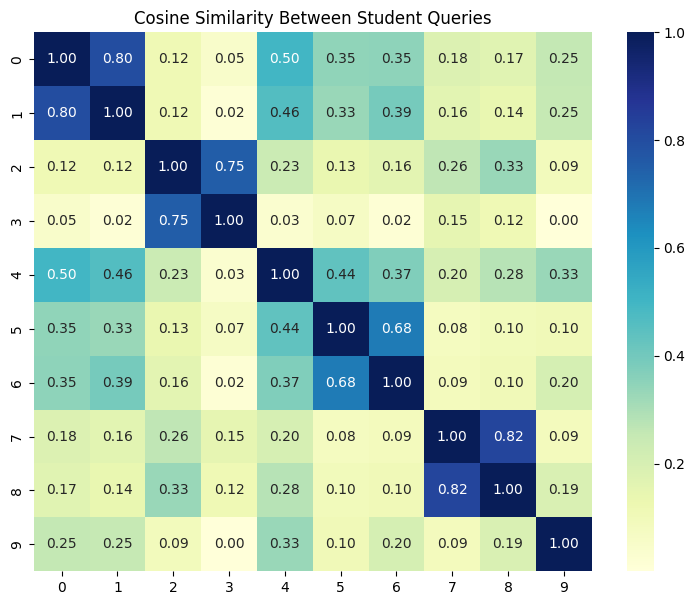

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 7))
sns.heatmap(sim_matrix, annot=True, fmt=".2f", cmap="YlGnBu",
            xticklabels=df["id"], yticklabels=df["id"])
plt.title("Cosine Similarity Between Student Queries")
plt.show()

In [12]:
import numpy as np

THRESHOLD = 0.60

def find_duplicates(sim_matrix, df, threshold=THRESHOLD):
    pairs = []
    n = len(df)
    for i in range(n):
        for j in range(i + 1, n):
            score = sim_matrix[i][j]
            if score >= threshold:
                pairs.append((df["question"][i], df["question"][j], round(float(score), 3)))
    return pairs

duplicates = find_duplicates(sim_matrix, df)

for q1, q2, s in sorted(duplicates, key=lambda x: -x[2]):
    print(f"Score: {s}\n  Q1: {q1}\n  Q2: {q2}\n")

Score: 0.822
  Q1: How to apply for a bonafide certificate?
  Q2: Process to get a bonafide certificate from college

Score: 0.798
  Q1: What is the deadline for assignment submission?
  Q2: When is the last date to submit the assignment?

Score: 0.75
  Q1: How do I reset my college portal password?
  Q2: I forgot my portal password, how can I recover it?

Score: 0.676
  Q1: Where can I find the library timings?
  Q2: What time does the library open?



In [13]:
def check_duplicate(new_question, df, embeddings, model, threshold=0.75, top_k=3):
    new_emb = model.encode([preprocess(new_question)])
    scores = cosine_similarity(new_emb, embeddings)[0]
    top_idx = np.argsort(scores)[::-1][:top_k]

    print(f"New question: {new_question}\n")
    for idx in top_idx:
        label = "DUPLICATE" if scores[idx] >= threshold else "Not duplicate"
        print(f"  [{label}] {scores[idx]:.3f} -> {df['question'][idx]}")

check_duplicate("How can I get my password back for the portal?", df, embeddings, model)

New question: How can I get my password back for the portal?

  [DUPLICATE] 0.895 -> I forgot my portal password, how can I recover it?
  [DUPLICATE] 0.760 -> How do I reset my college portal password?
  [Not duplicate] 0.132 -> How to apply for a bonafide certificate?


In [14]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

# (question1, question2, label)  1 = duplicate, 0 = not duplicate
test_pairs = [
    ("What is the deadline for assignment submission?", "When is the last date to submit the assignment?", 1),
    ("How do I reset my college portal password?", "I forgot my portal password, how can I recover it?", 1),
    ("What time does the library open?", "Where can I find the library timings?", 1),
    ("What are the exam timings for semester 5?", "How to apply for a bonafide certificate?", 0),
    ("Is attendance mandatory for lab sessions?", "How do I reset my college portal password?", 0),
    ("What is the deadline for assignment submission?", "What time does the library open?", 0),
]

y_true, y_scores = [], []
for q1, q2, label in test_pairs:
    e = model.encode([preprocess(q1), preprocess(q2)])
    y_scores.append(cosine_similarity([e[0]], [e[1]])[0][0])
    y_true.append(label)

y_pred = [1 if s >= THRESHOLD else 0 for s in y_scores]

print("Accuracy :", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred))
print("Recall   :", recall_score(y_true, y_pred))
print("F1-score :", f1_score(y_true, y_pred))

Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-score : 1.0


In [15]:
for t in [0.5, 0.6, 0.7, 0.75, 0.8, 0.85, 0.9]:
    preds = [1 if s >= t else 0 for s in y_scores]
    print(f"Threshold {t}: F1 = {f1_score(y_true, preds):.2f}")

Threshold 0.5: F1 = 1.00
Threshold 0.6: F1 = 1.00
Threshold 0.7: F1 = 0.80
Threshold 0.75: F1 = 0.80
Threshold 0.8: F1 = 0.00
Threshold 0.85: F1 = 0.00
Threshold 0.9: F1 = 0.00


In [ ]:
import gradio as gr
gr.close_all()   # closes old running interfaces

def app(q):
    new_emb = model.encode([preprocess(q)])
    scores = cosine_similarity(new_emb, embeddings)[0]
    i = int(np.argmax(scores))
    verdict = "Duplicate" if scores[i] >= THRESHOLD else "Unique question"
    return f"{verdict}\nClosest match: {df['question'][i]}\nScore: {scores[i]:.3f}"

demo = gr.Interface(fn=app, inputs="text", outputs="text",
                    title="Duplicate Question Detector")
demo.launch(share=True, debug=True)

Closing server running on port: 7861
Closing server running on port: 7860
Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://bff0817606f2f70e2f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
